# 02 — Algorithmic Customer Segmentation

## Objective

The objective of this workstream is to replace the existing loyalty-tier classification with a behaviour-based customer segmentation that marketing can act on.

The segmentation will:

1. Build a customer-level feature table using RFM and behavioural features.
2. Apply appropriate transformations to skewed variables.
3. Standardise features before distance-based clustering.
4. Evaluate K-Means for k = 2 to 10.
5. Compare K-Means with an alternative clustering algorithm.
6. Visualise cluster separation using PCA.
7. Test cluster stability across random seeds and a 70% sample.
8. Compare algorithmic segments with the existing loyalty tier.
9. Profile and name the resulting segments.
10. Recommend a marketing action for each segment.

### Expected outcome

A defensible 4–6 segment solution with clear behavioural differences and actionable business interpretations.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
PROJECT_ROOT = Path.cwd().parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

FIGURES_PATH = PROJECT_ROOT / "outputs" / "figures" / "segmentation"
TABLES_PATH = PROJECT_ROOT / "outputs" / "tables"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

In [3]:
orders = pd.read_csv(
    PROCESSED_DATA_PATH / "orders.csv",
    parse_dates=["order_datetime"]
)

customer_overview = pd.read_csv(
    PROCESSED_DATA_PATH / "customer_overview.csv",
    parse_dates=[
        "first_order_date",
        "last_order_date",
        "signup_date"
    ]
)

# Load original master/product/transaction data
customers = pd.read_csv(
    RAW_DATA_PATH / "customers.csv",
    parse_dates=["signup_date"]
)

products = pd.read_csv(
    RAW_DATA_PATH / "products.csv"
)

transactions = pd.read_csv(
    RAW_DATA_PATH / "transactions.csv",
    parse_dates=["order_date", "order_datetime"]
)

print("Data loaded successfully.")

Data loaded successfully.


In [4]:
print("Orders:", orders.shape)
print("Customer overview:", customer_overview.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Transactions:", transactions.shape)

Orders: (158115, 9)
Customer overview: (10965, 20)
Customers: (12000, 12)
Products: (391, 9)
Transactions: (575516, 15)


# Feature engineering

## We need to create the real segmentation feature table.

In [5]:
REFERENCE_DATE = transactions["order_datetime"].max()

print("Segmentation reference date:", REFERENCE_DATE)

Segmentation reference date: 2026-07-31 23:58:00


In [6]:
rfm = (
    orders
    .groupby("customer_id")
    .agg(
        last_order_date=("order_datetime", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_value", "sum"),
        average_order_value=("order_value", "mean")
    )
    .reset_index()
)

rfm["recency"] = (
    REFERENCE_DATE - rfm["last_order_date"]
).dt.days

rfm.head()

,customer_id,last_order_date,frequency,monetary,average_order_value,recency
0,CUST100000,2026-05-22 17:51:00,10,"2,828.230",282.823,70
1,CUST100001,2026-07-26 17:04:00,38,"27,700.390",728.958,5
2,CUST100002,2024-09-19 14:14:00,2,"1,821.720",910.860,680
3,CUST100003,2025-11-12 17:13:00,3,684.220,228.073,261
4,CUST100004,2026-07-16 12:24:00,34,"18,344.380",539.541,15


In [7]:
rfm[
    [
        "recency",
        "frequency",
        "monetary",
        "average_order_value"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
recency,"10,965.000",165.644,205.991,0.000,16.000,58.000,266.000,728.000
frequency,"10,965.000",14.420,13.915,1.000,4.000,10.000,20.000,120.000
monetary,"10,965.000","4,540.250","5,757.900",4.450,858.630,"2,564.020","5,943.020","71,953.200"
average_order_value,"10,965.000",323.442,274.897,4.305,130.560,219.219,466.443,"3,440.010"


In [8]:
rfm = rfm[
    [
        "customer_id",
        "recency",
        "frequency",
        "monetary",
        "average_order_value",
        "last_order_date"
    ]
]

In [9]:
basic_behavior = (
    orders
    .groupby("customer_id")
    .agg(
        average_basket_size=("units", "mean"),
        average_discount=("avg_discount", "mean"),
        total_units=("units", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

basic_behavior.head()

,customer_id,average_basket_size,average_discount,total_units,total_orders
0,CUST100000,3.700,6.667,37,10
1,CUST100001,6.789,2.970,258,38
2,CUST100002,12.000,1.071,24,2
3,CUST100003,8.000,2.560,24,3
4,CUST100004,7.912,1.923,269,34


In [10]:
orders["day_of_week"] = orders["order_datetime"].dt.dayofweek

orders["is_weekend"] = (
    orders["day_of_week"] >= 5
).astype(int)

In [11]:
weekend_share = (
    orders
    .groupby("customer_id")
    .agg(
        weekend_order_share=("is_weekend", "mean")
    )
    .reset_index()
)

weekend_share.head()

,customer_id,weekend_order_share
0,CUST100000,0.200
1,CUST100001,0.421
2,CUST100002,0.500
3,CUST100003,0.000
4,CUST100004,0.294


In [12]:
print(transactions["channel"].value_counts(dropna=False))

channel
In-Store       198367
Mobile App     151519
Web            149022
Marketplace     60308
Call Centre     16300
Name: count, dtype: int64


In [13]:
print(orders["channel"].value_counts(dropna=False))

channel
In-Store       47546
Mobile App     46662
Web            41761
Marketplace    17846
Call Centre     4300
Name: count, dtype: int64


In [14]:
channel_counts = pd.crosstab(
    orders["customer_id"],
    orders["channel"],
    normalize="index"
)

channel_counts.columns = [
    f"channel_share_{str(col).lower().replace(' ', '_')}"
    for col in channel_counts.columns
]

channel_counts = channel_counts.reset_index()

channel_counts.head()

,customer_id,channel_share_call_centre,channel_share_in-store,channel_share_marketplace,channel_share_mobile_app,channel_share_web
0,CUST100000,0.000,0.100,0.000,0.300,0.600
1,CUST100001,0.000,0.342,0.026,0.368,0.263
2,CUST100002,0.000,0.500,0.500,0.000,0.000
3,CUST100003,0.000,0.333,0.333,0.000,0.333
4,CUST100004,0.000,0.353,0.029,0.265,0.353


In [15]:
transaction_products = transactions[
    [
        "order_id",
        "customer_id",
        "product_id",
        "line_revenue_aed"
    ]
].merge(
    products[
        [
            "product_id",
            "category",
            "is_private_label"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

transaction_products.head()

,order_id,customer_id,product_id,line_revenue_aed,category,is_private_label
0,ORD1134957,CUST110195,SKU100145,21.450,Fresh Food,1
1,ORD1134957,CUST110195,SKU100156,11.450,Fresh Food,1
2,ORD1134957,CUST110195,SKU100015,22.450,Grocery,0
3,ORD1132788,CUST110039,SKU100100,7.950,Beverages,1
4,ORD1132788,CUST110039,SKU100078,15.950,Beverages,0


In [16]:
print(
    "Transactions with missing category:",
    transaction_products["category"].isna().sum()
)

Transactions with missing category: 0


In [17]:
category_spend = (
    transaction_products
    .groupby(
        ["customer_id", "category"]
    )["line_revenue_aed"]
    .sum()
    .reset_index()
)

category_spend.head()

,customer_id,category,line_revenue_aed
0,CUST100000,Baby,45.820
1,CUST100000,Beverages,75.890
2,CUST100000,Fresh Food,19.080
3,CUST100000,Grocery,47.800
4,CUST100000,Health & Wellness,"2,032.950"


In [18]:
category_spend["customer_total_spend"] = (
    category_spend
    .groupby("customer_id")["line_revenue_aed"]
    .transform("sum")
)

category_spend["category_spend_share"] = (
    category_spend["line_revenue_aed"] /
    category_spend["customer_total_spend"]
)

In [19]:
category_pivot = (
    category_spend
    .pivot(
        index="customer_id",
        columns="category",
        values="category_spend_share"
    )
    .fillna(0)
)

category_pivot.columns = [
    f"category_share_{str(col).lower().replace(' ', '_')}"
    for col in category_pivot.columns
]

category_pivot = category_pivot.reset_index()

category_pivot.head()

,customer_id,category_share_baby,category_share_beverages,category_share_fresh_food,category_share_grocery,category_share_health_&_wellness,category_share_home_&_living,category_share_household,category_share_personal_care,category_share_pet_care,category_share_snacks
0,CUST100000,0.016,0.027,0.007,0.017,0.719,0.000,0.002,0.156,0.057,0.000
1,CUST100001,0.082,0.013,0.043,0.012,0.035,0.703,0.022,0.037,0.037,0.014
2,CUST100002,0.027,0.000,0.054,0.087,0.000,0.508,0.059,0.243,0.016,0.006
3,CUST100003,0.039,0.000,0.285,0.151,0.000,0.103,0.122,0.047,0.252,0.000
4,CUST100004,0.183,0.045,0.056,0.022,0.048,0.393,0.024,0.138,0.049,0.042


In [20]:
private_label_share = (
    transaction_products
    .groupby("customer_id")
    .apply(
        lambda x: np.average(
            x["is_private_label"].astype(float),
            weights=x["line_revenue_aed"]
        )
    )
    .reset_index(name="private_label_spend_share")
)

private_label_share.head()

,customer_id,private_label_spend_share
0,CUST100000,0.145
1,CUST100001,0.041
2,CUST100002,0.095
3,CUST100003,0.099
4,CUST100004,0.068


In [21]:
customer_dates = customers[
    ["customer_id", "signup_date"]
].copy()

customer_dates["tenure_months"] = (
    (REFERENCE_DATE - customer_dates["signup_date"])
    .dt.days / 30.44
)

customer_dates["tenure_months"] = (
    customer_dates["tenure_months"]
    .clip(lower=0)
)

customer_dates.head()

,customer_id,signup_date,tenure_months
0,CUST100000,2025-07-17,12.451
1,CUST100001,2024-10-03,21.879
2,CUST100002,2022-03-07,52.792
3,CUST100003,2025-09-16,10.447
4,CUST100004,2022-09-04,46.846


In [22]:
customer_features = rfm.merge(
    basic_behavior,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    weekend_share,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    channel_counts,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    category_pivot,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    private_label_share,
    on="customer_id",
    how="left"
)

customer_features = customer_features.merge(
    customer_dates,
    on="customer_id",
    how="left"
)

In [23]:
customer_features = customer_features.merge(
    customers[
        ["customer_id", "loyalty_tier"]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

In [24]:
print("Customer feature table shape:", customer_features.shape)

display(customer_features.head())

Customer feature table shape: (10965, 30)


,customer_id,recency,frequency,monetary,average_order_value,last_order_date,average_basket_size,average_discount,total_units,total_orders,weekend_order_share,channel_share_call_centre,channel_share_in-store,channel_share_marketplace,channel_share_mobile_app,channel_share_web,category_share_baby,category_share_beverages,category_share_fresh_food,category_share_grocery,category_share_health_&_wellness,category_share_home_&_living,category_share_household,category_share_personal_care,category_share_pet_care,category_share_snacks,private_label_spend_share,signup_date,tenure_months,loyalty_tier
0,CUST100000,70,10,"2,828.230",282.823,2026-05-22 17:51:00,3.700,6.667,37,10,0.200,0.000,0.100,0.000,0.300,0.600,0.016,0.027,0.007,0.017,0.719,0.000,0.002,0.156,0.057,0.000,0.145,2025-07-17,12.451,Silver
1,CUST100001,5,38,"27,700.390",728.958,2026-07-26 17:04:00,6.789,2.970,258,38,0.421,0.000,0.342,0.026,0.368,0.263,0.082,0.013,0.043,0.012,0.035,0.703,0.022,0.037,0.037,0.014,0.041,2024-10-03,21.879,Silver
2,CUST100002,680,2,"1,821.720",910.860,2024-09-19 14:14:00,12.000,1.071,24,2,0.500,0.000,0.500,0.500,0.000,0.000,0.027,0.000,0.054,0.087,0.000,0.508,0.059,0.243,0.016,0.006,0.095,2022-03-07,52.792,Gold
3,CUST100003,261,3,684.220,228.073,2025-11-12 17:13:00,8.000,2.560,24,3,0.000,0.000,0.333,0.333,0.000,0.333,0.039,0.000,0.285,0.151,0.000,0.103,0.122,0.047,0.252,0.000,0.099,2025-09-16,10.447,Gold
4,CUST100004,15,34,"18,344.380",539.541,2026-07-16 12:24:00,7.912,1.923,269,34,0.294,0.000,0.353,0.029,0.265,0.353,0.183,0.045,0.056,0.022,0.048,0.393,0.024,0.138,0.049,0.042,0.068,2022-09-04,46.846,Gold


# Handle skew

In [25]:
skew_features = [
    "recency",
    "frequency",
    "monetary",
    "average_order_value",
    "average_basket_size",
    "total_units"
]

customer_features[skew_features].skew().sort_values(ascending=False)

monetary              2.882
average_order_value   2.338
total_units           2.034
average_basket_size   2.032
frequency             1.839
recency               1.276
dtype: float64

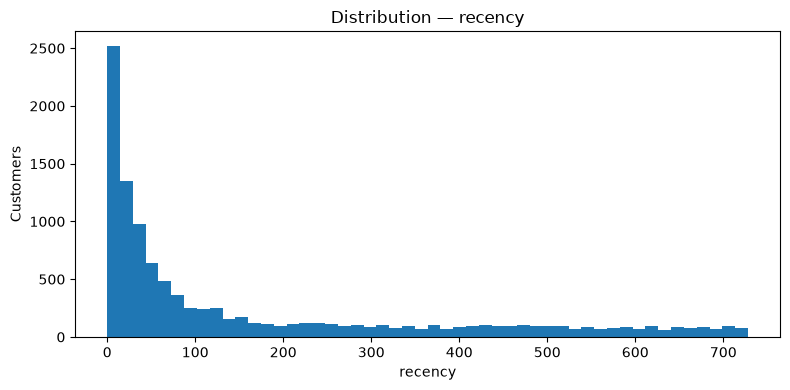

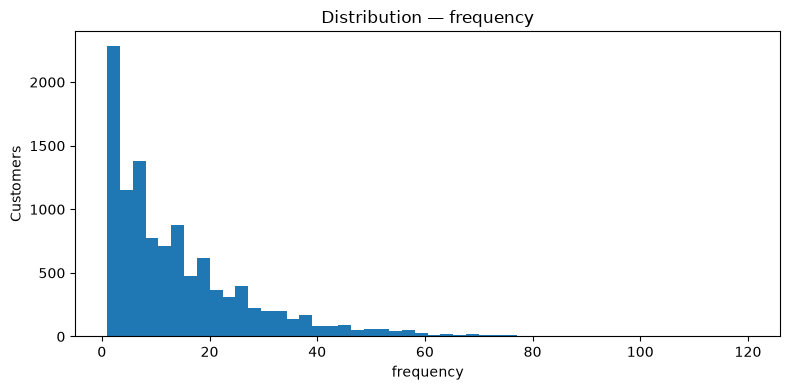

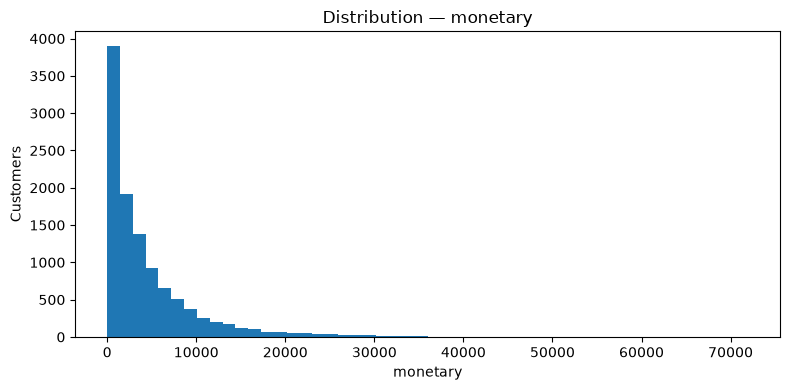

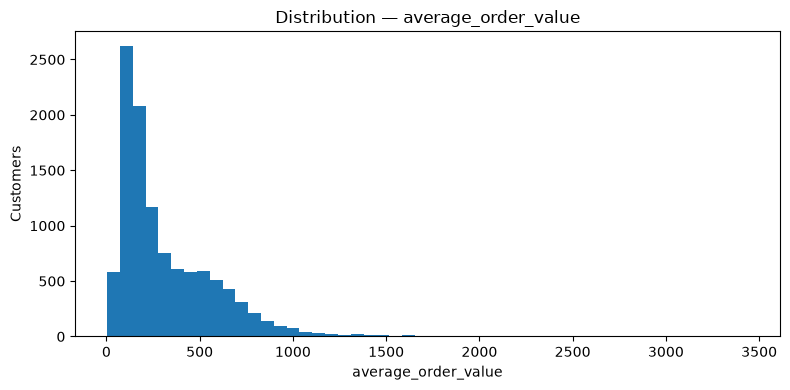

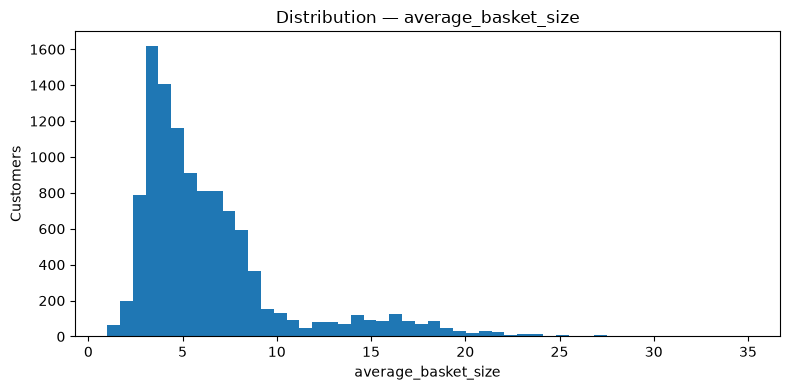

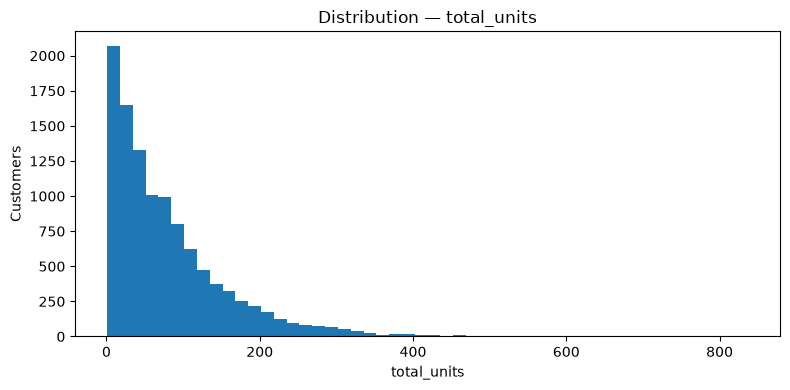

In [26]:
for feature in skew_features:
    
    plt.figure(figsize=(8, 4))
    
    plt.hist(
        customer_features[feature].dropna(),
        bins=50
    )
    
    plt.xlabel(feature)
    plt.ylabel("Customers")
    plt.title(f"Distribution — {feature}")
    
    plt.tight_layout()
    plt.show()

In [27]:
log_features = [
    "recency",
    "frequency",
    "monetary",
    "average_order_value",
    "average_basket_size",
    "total_units"
]

for feature in log_features:
    customer_features[f"log_{feature}"] = np.log1p(
        customer_features[feature]
    )

In [28]:
skew_comparison = pd.DataFrame({
    "Before": customer_features[log_features].skew().values,
    "After": customer_features[
        [f"log_{f}" for f in log_features]
    ].skew().values
}, index=log_features)

skew_comparison

,Before,After
recency,1.276,-0.322
frequency,1.839,-0.117
monetary,2.882,-0.627
average_order_value,2.338,-0.103
average_basket_size,2.032,0.704
total_units,2.034,-0.478


# Scaling

In [29]:
model_features = [
    "log_recency",
    "log_frequency",
    "log_monetary",
    "log_average_order_value",
    "log_average_basket_size",
    "log_total_units",
    "average_discount",
    "weekend_order_share",
    "private_label_spend_share",
    "tenure_months"
]

In [30]:
channel_features = [
    col for col in customer_features.columns
    if col.startswith("channel_share_")
]

model_features.extend(channel_features)

In [31]:
category_features = [
    col for col in customer_features.columns
    if col.startswith("category_share_")
]

model_features.extend(category_features)

In [32]:
print("Number of clustering features:", len(model_features))
print(model_features)

Number of clustering features: 25
['log_recency', 'log_frequency', 'log_monetary', 'log_average_order_value', 'log_average_basket_size', 'log_total_units', 'average_discount', 'weekend_order_share', 'private_label_spend_share', 'tenure_months', 'channel_share_call_centre', 'channel_share_in-store', 'channel_share_marketplace', 'channel_share_mobile_app', 'channel_share_web', 'category_share_baby', 'category_share_beverages', 'category_share_fresh_food', 'category_share_grocery', 'category_share_health_&_wellness', 'category_share_home_&_living', 'category_share_household', 'category_share_personal_care', 'category_share_pet_care', 'category_share_snacks']


In [33]:
X = customer_features[model_features].copy()

print("Missing values before treatment:", X.isna().sum().sum())

Missing values before treatment: 0


In [34]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=customer_features["customer_id"]
)

X_scaled.head()

,log_recency,log_frequency,log_monetary,log_average_order_value,log_average_basket_size,log_total_units,average_discount,weekend_order_share,private_label_spend_share,tenure_months,channel_share_call_centre,channel_share_in-store,channel_share_marketplace,channel_share_mobile_app,channel_share_web,category_share_baby,category_share_beverages,category_share_fresh_food,category_share_grocery,category_share_health_&_wellness,category_share_home_&_living,category_share_household,category_share_personal_care,category_share_pet_care,category_share_snacks
customer_id,,,,,,,,,,,,,,,,,,,,,,,,,
CUST100000,0.117,0.055,0.212,0.220,-0.778,-0.273,1.534,-0.404,0.144,-0.707,-0.383,-0.929,-0.763,0.164,1.670,-0.556,-0.489,-0.755,-0.423,3.067,-0.968,-0.597,-0.068,-0.292,-0.725
CUST100001,-1.350,1.434,1.805,1.395,0.348,1.515,-0.091,0.665,-0.667,-0.068,-0.383,-0.036,-0.582,0.439,0.054,0.067,-0.628,-0.312,-0.474,-0.476,2.140,-0.401,-0.814,-0.461,-0.558
CUST100002,1.460,-1.361,-0.095,1.672,1.490,-0.663,-0.926,1.046,-0.249,2.026,-0.383,0.546,2.689,-1.041,-1.208,-0.451,-0.763,-0.175,0.368,-0.655,1.280,-0.036,0.480,-0.650,-0.660
CUST100003,0.893,-1.047,-0.777,-0.047,0.670,-0.663,-0.272,-1.372,-0.219,-0.843,-0.383,-0.068,1.538,-1.041,0.391,-0.338,-0.763,2.652,1.097,-0.655,-0.512,0.580,-0.753,1.425,-0.725
CUST100004,-0.767,1.316,1.517,1.021,0.648,1.554,-0.552,0.051,-0.464,1.623,-0.383,0.004,-0.560,0.022,0.485,1.014,-0.307,-0.150,-0.364,-0.405,0.770,-0.383,-0.178,-0.363,-0.241


In [35]:
print("Mean:")
display(X_scaled.mean().round(3))

print("Standard deviation:")
display(X_scaled.std().round(3))

Mean:


log_recency                        -0.000
log_frequency                      -0.000
log_monetary                       -0.000
log_average_order_value             0.000
log_average_basket_size             0.000
log_total_units                    -0.000
average_discount                    0.000
weekend_order_share                 0.000
private_label_spend_share          -0.000
tenure_months                      -0.000
channel_share_call_centre           0.000
channel_share_in-store              0.000
channel_share_marketplace          -0.000
channel_share_mobile_app            0.000
channel_share_web                  -0.000
category_share_baby                -0.000
category_share_beverages           -0.000
category_share_fresh_food          -0.000
category_share_grocery              0.000
category_share_health_&_wellness    0.000
category_share_home_&_living        0.000
category_share_household           -0.000
category_share_personal_care       -0.000
category_share_pet_care           

Standard deviation:


log_recency                        1.000
log_frequency                      1.000
log_monetary                       1.000
log_average_order_value            1.000
log_average_basket_size            1.000
log_total_units                    1.000
average_discount                   1.000
weekend_order_share                1.000
private_label_spend_share          1.000
tenure_months                      1.000
channel_share_call_centre          1.000
channel_share_in-store             1.000
channel_share_marketplace          1.000
channel_share_mobile_app           1.000
channel_share_web                  1.000
category_share_baby                1.000
category_share_beverages           1.000
category_share_fresh_food          1.000
category_share_grocery             1.000
category_share_health_&_wellness   1.000
category_share_home_&_living       1.000
category_share_household           1.000
category_share_personal_care       1.000
category_share_pet_care            1.000
category_share_s

# kmeans clustering

In [36]:
k_results = []

for k in range(2, 11):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    k_results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette": silhouette_score(
            X_scaled,
            labels
        )
    })

k_results = pd.DataFrame(k_results)

k_results

,k,inertia,silhouette
0,2,"242,507.888",0.177
1,3,"222,853.669",0.101
2,4,"213,530.145",0.075
3,5,"205,569.211",0.097
4,6,"198,705.458",0.079
5,7,"193,240.459",0.088
6,8,"187,500.369",0.089
7,9,"182,668.251",0.095
8,10,"177,568.097",0.100


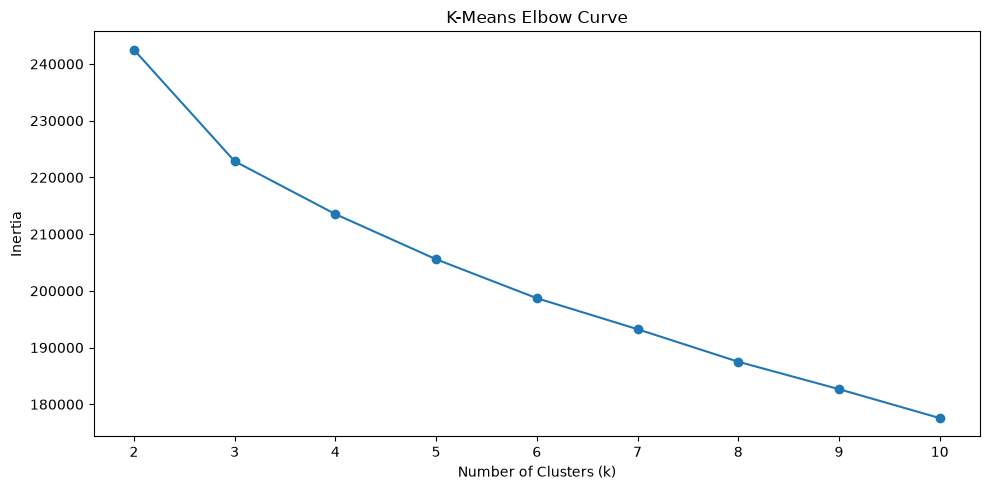

In [37]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_results["k"],
    k_results["inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")

plt.xticks(range(2, 11))
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "kmeans_elbow.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

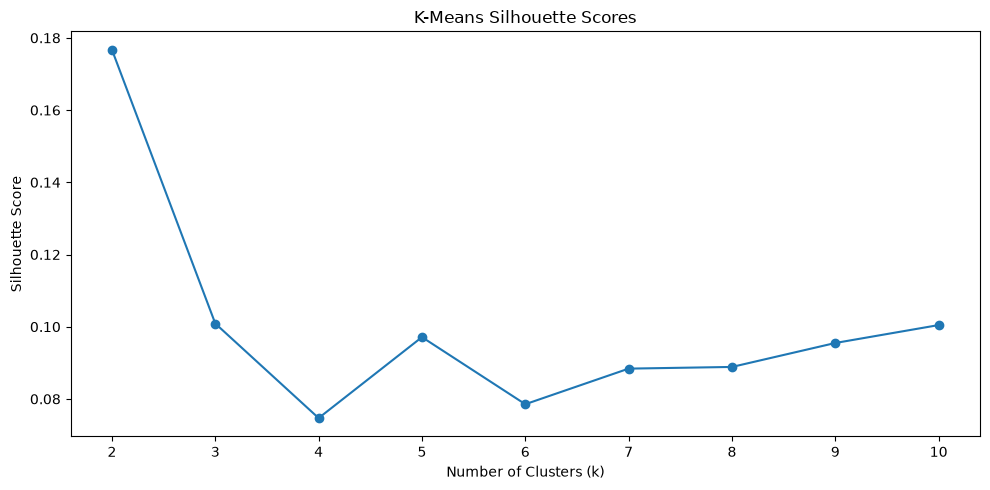

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(
    k_results["k"],
    k_results["silhouette"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Scores")

plt.xticks(range(2, 11))
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "kmeans_silhouette.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [39]:
best_silhouette_k = (
    k_results
    .loc[k_results["silhouette"].idxmax(), "k"]
)

print(
    "Best K by silhouette:",
    best_silhouette_k
)

Best K by silhouette: 2


In [40]:
k_results[
    k_results["k"].isin([3, 4, 5, 6])
].sort_values("k")

,k,inertia,silhouette
1,3,"222,853.669",0.101
2,4,"213,530.145",0.075
3,5,"205,569.211",0.097
4,6,"198,705.458",0.079


In [41]:
for k in [3, 4, 5, 6]:
    
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    
    labels = model.fit_predict(X_scaled)
    
    sizes = pd.Series(labels).value_counts().sort_index()
    
    print(f"\nK = {k}")
    print(f"Silhouette = {silhouette_score(X_scaled, labels):.4f}")
    print("Cluster sizes:")
    print(sizes.to_dict())


K = 3
Silhouette = 0.1009
Cluster sizes:
{0: 2986, 1: 3697, 2: 4282}

K = 4
Silhouette = 0.0747
Cluster sizes:
{0: 3479, 1: 2534, 2: 2957, 3: 1995}

K = 5
Silhouette = 0.0971
Cluster sizes:
{0: 2389, 1: 3025, 2: 1320, 3: 1631, 4: 2600}

K = 6
Silhouette = 0.0785
Cluster sizes:
{0: 2962, 1: 2174, 2: 1426, 3: 1276, 4: 849, 5: 2278}


In [42]:
FINAL_K = 5

kmeans_5 = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20
)

labels_5 = kmeans_5.fit_predict(X_scaled)

customer_features["cluster_5"] = labels_5

In [43]:
profile_5 = (
    customer_features
    .groupby("cluster_5")
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        median_aov=("average_order_value", "median"),
        median_basket=("average_basket_size", "median"),
        median_discount=("average_discount", "median"),
        median_weekend_share=("weekend_order_share", "median"),
        median_private_label_share=(
            "private_label_spend_share",
            "median"
        ),
        median_tenure=("tenure_months", "median")
    )
    .reset_index()
)

profile_5

,cluster_5,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket,median_discount,median_weekend_share,median_private_label_share,median_tenure
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894


In [44]:
profile_5.set_index("cluster_5").T

cluster_5,0,1,2,3,4
customers,"2,389.000","3,025.000","1,320.000","1,631.000","2,600.000"
median_recency,145.000,35.000,310.500,57.000,26.000
median_frequency,6.000,14.000,2.000,9.000,21.000
median_monetary,"1,208.890","7,715.200",218.630,"2,327.310","3,208.385"
median_aov,181.070,586.036,85.552,243.621,155.595
median_basket,6.667,7.615,4.667,4.233,3.479
median_discount,3.979,2.510,3.333,2.500,2.514
median_weekend_share,0.250,0.278,0.200,0.267,0.281
median_private_label_share,0.149,0.061,0.225,0.076,0.090
median_tenure,19.021,21.124,15.128,19.218,20.894


In [45]:
feature_centers = pd.DataFrame(
    kmeans_5.cluster_centers_,
    columns=model_features
)

feature_centers.T

,0,1,2,3,4
log_recency,0.400,-0.273,0.705,0.018,-0.420
log_frequency,-0.484,0.340,-1.161,-0.051,0.671
log_monetary,-0.421,0.883,-1.649,-0.013,0.205
log_average_order_value,-0.117,1.099,-1.325,0.020,-0.511
log_average_basket_size,0.676,0.647,-0.391,-0.530,-0.844
log_total_units,-0.148,0.653,-1.327,-0.282,0.227
average_discount,0.393,-0.195,0.406,-0.199,-0.215
weekend_order_share,0.009,-0.015,0.009,-0.005,0.008
private_label_spend_share,0.275,-0.411,1.144,-0.288,-0.175
tenure_months,-0.050,0.112,-0.285,-0.042,0.087


In [46]:
feature_separation = (
    feature_centers.max()
    - feature_centers.min()
).sort_values(ascending=False)

feature_separation.head(15)

log_monetary                       2.532
category_share_health_&_wellness   2.504
log_average_order_value            2.423
log_total_units                    1.980
category_share_home_&_living       1.905
log_frequency                      1.832
private_label_spend_share          1.554
log_average_basket_size            1.520
channel_share_in-store             1.473
category_share_snacks              1.470
category_share_grocery             1.437
category_share_baby                1.392
category_share_household           1.369
category_share_personal_care       1.245
log_recency                        1.125
dtype: float64

In [47]:
# Show the complete feature separation ranking

feature_separation.to_frame(
    name="cluster_separation"
)

,cluster_separation
log_monetary,2.532
category_share_health_&_wellness,2.504
log_average_order_value,2.423
log_total_units,1.980
category_share_home_&_living,1.905
log_frequency,1.832
private_label_spend_share,1.554
log_average_basket_size,1.520
channel_share_in-store,1.473
category_share_snacks,1.470


In [48]:
# Show category features separately

category_separation = (
    feature_separation[
        feature_separation.index.str.startswith(
            "category_share_"
        )
    ]
    .sort_values(ascending=False)
)

category_separation

category_share_health_&_wellness   2.504
category_share_home_&_living       1.905
category_share_snacks              1.470
category_share_grocery             1.437
category_share_baby                1.392
category_share_household           1.369
category_share_personal_care       1.245
category_share_fresh_food          1.000
category_share_pet_care            0.997
category_share_beverages           0.924
dtype: float64

In [49]:
# Show non-category features separately

non_category_separation = (
    feature_separation[
        ~feature_separation.index.str.startswith(
            "category_share_"
        )
    ]
    .sort_values(ascending=False)
)

non_category_separation

log_monetary                2.532
log_average_order_value     2.423
log_total_units             1.980
log_frequency               1.832
private_label_spend_share   1.554
log_average_basket_size     1.520
channel_share_in-store      1.473
log_recency                 1.125
channel_share_mobile_app    1.112
channel_share_web           0.820
average_discount            0.622
tenure_months               0.397
channel_share_marketplace   0.373
channel_share_call_centre   0.170
weekend_order_share         0.024
dtype: float64

In [50]:
profile_5

,cluster_5,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket,median_discount,median_weekend_share,median_private_label_share,median_tenure
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894


In [51]:
category_cluster_profile = (
    customer_features
    .groupby("cluster_5")[category_features]
    .median()
)

category_cluster_profile

,category_share_baby,category_share_beverages,category_share_fresh_food,category_share_grocery,category_share_health_&_wellness,category_share_home_&_living,category_share_household,category_share_personal_care,category_share_pet_care,category_share_snacks
cluster_5,,,,,,,,,,
0,0.128,0.042,0.052,0.072,0.009,0.075,0.102,0.079,0.119,0.062
1,0.101,0.029,0.052,0.026,0.033,0.479,0.026,0.115,0.050,0.024
2,0.000,0.029,0.081,0.088,0.000,0.000,0.080,0.000,0.000,0.084
3,0.000,0.039,0.052,0.014,0.505,0.023,0.012,0.130,0.026,0.005
4,0.001,0.107,0.046,0.023,0.072,0.124,0.019,0.275,0.083,0.075


In [52]:
category_cluster_profile.T

cluster_5,0,1,2,3,4
category_share_baby,0.128,0.101,0.000,0.000,0.001
category_share_beverages,0.042,0.029,0.029,0.039,0.107
category_share_fresh_food,0.052,0.052,0.081,0.052,0.046
category_share_grocery,0.072,0.026,0.088,0.014,0.023
category_share_health_&_wellness,0.009,0.033,0.000,0.505,0.072
category_share_home_&_living,0.075,0.479,0.000,0.023,0.124
category_share_household,0.102,0.026,0.080,0.012,0.019
category_share_personal_care,0.079,0.115,0.000,0.130,0.275
category_share_pet_care,0.119,0.050,0.000,0.026,0.083
category_share_snacks,0.062,0.024,0.084,0.005,0.075


In [54]:
FINAL_K = 5

print("Initial selected K:", FINAL_K)

Initial selected K: 5


In [55]:
gmm = GaussianMixture(
    n_components=FINAL_K,
    covariance_type="full",
    random_state=42,
    n_init=10
)

gmm_labels = gmm.fit_predict(X_scaled)

gmm_silhouette = silhouette_score(
    X_scaled,
    gmm_labels
)

print("GMM silhouette:", gmm_silhouette)

GMM silhouette: 0.01689352644634129


In [56]:
kmeans_final = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Gaussian Mixture"
    ],
    "Clusters": [
        FINAL_K,
        FINAL_K
    ],
    "Silhouette": [
        kmeans_silhouette,
        gmm_silhouette
    ]
})

comparison

,Algorithm,Clusters,Silhouette
0,K-Means,5,0.097
1,Gaussian Mixture,5,0.017


In [57]:
print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

print("\nGMM cluster sizes:")
print(pd.Series(gmm_labels).value_counts().sort_index())

K-Means cluster sizes:
0    2389
1    3025
2    1320
3    1631
4    2600
Name: count, dtype: int64

GMM cluster sizes:
0    2425
1    1084
2    4250
3    1842
4    1364
Name: count, dtype: int64


In [58]:
if gmm_silhouette > kmeans_silhouette:
    FINAL_ALGORITHM = "GMM"
    final_labels = gmm_labels
else:
    FINAL_ALGORITHM = "K-Means"
    final_labels = kmeans_labels

print("Selected algorithm:", FINAL_ALGORITHM)

Selected algorithm: K-Means


# PCA visualization

In [59]:
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained:",
    pca.explained_variance_ratio_
)

print(
    "Total variance explained:",
    pca.explained_variance_ratio_.sum()
)

Variance explained: [0.17463507 0.1198556 ]
Total variance explained: 0.2944906733271875


In [60]:
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": final_labels
})

pca_df.head()

,PC1,PC2,cluster
0,0.095,-1.813,3
1,3.932,0.689,1
2,0.363,2.054,1
3,-1.900,1.247,0
4,3.254,0.675,1


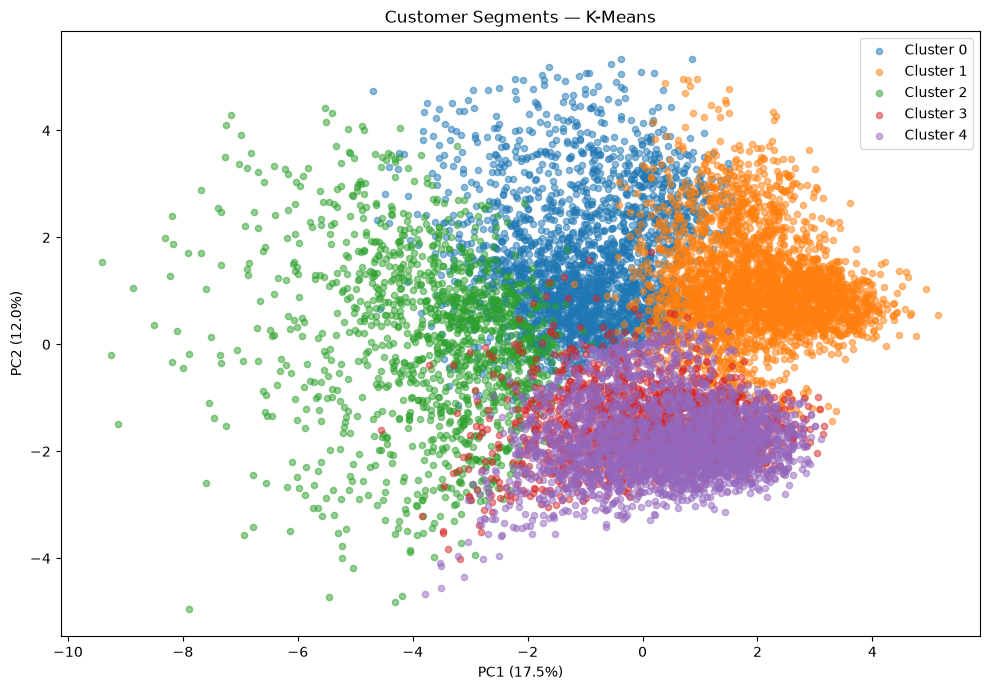

In [61]:
plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df["cluster"].unique()):
    
    subset = pca_df[
        pca_df["cluster"] == cluster
    ]
    
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.5,
        s=20
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)"
)

plt.title(
    f"Customer Segments — {FINAL_ALGORITHM}"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "pca_customer_segments.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [62]:
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=model_features,
    columns=["PC1", "PC2"]
)

pca_loadings["absolute_loading_PC1"] = (
    pca_loadings["PC1"].abs()
)

pca_loadings["absolute_loading_PC2"] = (
    pca_loadings["PC2"].abs()
)

pca_loadings.sort_values(
    "absolute_loading_PC1",
    ascending=False
).head(10)

,PC1,PC2,absolute_loading_PC1,absolute_loading_PC2
log_monetary,0.464,0.007,0.464,0.007
log_total_units,0.396,0.045,0.396,0.045
log_frequency,0.353,-0.178,0.353,0.178
log_average_order_value,0.348,0.248,0.348,0.248
category_share_home_&_living,0.295,0.176,0.295,0.176
private_label_spend_share,-0.232,0.069,0.232,0.069
log_recency,-0.229,0.126,0.229,0.126
category_share_grocery,-0.213,0.145,0.213,0.145
category_share_household,-0.196,0.177,0.196,0.177
category_share_snacks,-0.171,-0.043,0.171,0.043


# cluster stability

In [63]:
seed_labels = {}

seeds = [0, 7, 21, 42, 99]

for seed in seeds:
    
    model = KMeans(
        n_clusters=FINAL_K,
        random_state=seed,
        n_init=20
    )
    
    seed_labels[seed] = model.fit_predict(X_scaled)

In [64]:
stability_results = []

reference_labels = seed_labels[42]

for seed, labels in seed_labels.items():
    
    ari = adjusted_rand_score(
        reference_labels,
        labels
    )
    
    stability_results.append({
        "seed": seed,
        "ARI_vs_seed_42": ari
    })

seed_stability = pd.DataFrame(
    stability_results
)

seed_stability

,seed,ARI_vs_seed_42
0,0,0.999
1,7,1.000
2,21,1.000
3,42,1.000
4,99,0.995


# 70% sample stability

In [65]:
rng = np.random.default_rng(42)

sample_size = int(len(X_scaled) * 0.70)

sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled.iloc[sample_indices]

In [66]:
sample_model = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20
)

sample_labels = sample_model.fit_predict(
    X_sample
)

In [67]:
full_labels_for_sample = np.array(
    kmeans_labels
)[sample_indices]

sample_ari = adjusted_rand_score(
    full_labels_for_sample,
    sample_labels
)

print("70% sample ARI:", sample_ari)

70% sample ARI: 0.9651429922093087


In [68]:
customer_features["cluster"] = final_labels

In [69]:
loyalty_cluster = pd.crosstab(
    customer_features["loyalty_tier"],
    customer_features["cluster"],
    normalize="index"
) * 100

loyalty_cluster.round(2)

cluster,0,1,2,3,4
loyalty_tier,,,,,
Blue,29.030,8.190,23.720,9.410,29.650
Gold,19.780,36.930,7.490,16.590,19.210
Platinum,14.900,67.210,2.910,10.060,4.920
Silver,22.940,14.330,14.420,16.990,31.320


In [70]:
pd.crosstab(
    customer_features["loyalty_tier"],
    customer_features["cluster"]
)

cluster,0,1,2,3,4
loyalty_tier,,,,,
Blue,475,134,388,154,485
Gold,739,1380,280,620,718
Platinum,200,902,39,135,66
Silver,975,609,613,722,1331


In [71]:
cluster_loyalty = pd.crosstab(
    customer_features["cluster"],
    customer_features["loyalty_tier"],
    normalize="index"
) * 100

cluster_loyalty.round(2)

loyalty_tier,Blue,Gold,Platinum,Silver
cluster,,,,
0,19.880,30.930,8.370,40.810
1,4.430,45.620,29.820,20.130
2,29.390,21.210,2.950,46.440
3,9.440,38.010,8.280,44.270
4,18.650,27.620,2.540,51.190


In [72]:
customer_features["cluster"] = final_labels

In [73]:
cluster_profile = (
    customer_features
    .groupby("cluster")
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        median_aov=("average_order_value", "median"),
        median_basket_size=("average_basket_size", "median"),
        median_discount=("average_discount", "median"),
        median_weekend_share=("weekend_order_share", "median"),
        median_private_label_share=(
            "private_label_spend_share",
            "median"
        ),
        median_tenure_months=("tenure_months", "median")
    )
    .reset_index()
)

cluster_profile

,cluster,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket_size,median_discount,median_weekend_share,median_private_label_share,median_tenure_months
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894


In [74]:
cluster_profile["customer_percentage"] = (
    cluster_profile["customers"] /
    cluster_profile["customers"].sum() * 100
)

cluster_profile

,cluster,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket_size,median_discount,median_weekend_share,median_private_label_share,median_tenure_months,customer_percentage
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021,21.788
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124,27.588
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128,12.038
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218,14.875
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894,23.712


In [75]:
category_share_by_cluster = (
    customer_features
    .groupby("cluster")[category_features]
    .median()
)

top_categories = {}

for cluster in category_share_by_cluster.index:
    
    top_cols = (
        category_share_by_cluster
        .loc[cluster]
        .sort_values(ascending=False)
        .head(3)
    )
    
    top_categories[cluster] = [
        col.replace("category_share_", "")
        for col in top_cols.index
    ]

top_categories

{0: ['baby', 'pet_care', 'household'],
 1: ['home_&_living', 'personal_care', 'baby'],
 2: ['grocery', 'snacks', 'fresh_food'],
 3: ['health_&_wellness', 'personal_care', 'fresh_food'],
 4: ['personal_care', 'home_&_living', 'beverages']}

In [76]:
top_categories_df = pd.DataFrame([
    {
        "cluster": cluster,
        "top_category_1": categories[0],
        "top_category_2": categories[1],
        "top_category_3": categories[2]
    }
    for cluster, categories in top_categories.items()
])

top_categories_df

,cluster,top_category_1,top_category_2,top_category_3
0,0,baby,pet_care,household
1,1,home_&_living,personal_care,baby
2,2,grocery,snacks,fresh_food
3,3,health_&_wellness,personal_care,fresh_food
4,4,personal_care,home_&_living,beverages


In [77]:
cluster_profile = cluster_profile.merge(
    top_categories_df,
    on="cluster",
    how="left"
)

cluster_profile

,cluster,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket_size,median_discount,median_weekend_share,median_private_label_share,median_tenure_months,customer_percentage,top_category_1,top_category_2,top_category_3
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021,21.788,baby,pet_care,household
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124,27.588,home_&_living,personal_care,baby
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128,12.038,grocery,snacks,fresh_food
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218,14.875,health_&_wellness,personal_care,fresh_food
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894,23.712,personal_care,home_&_living,beverages


In [78]:
channel_cluster = (
    customer_features
    .groupby("cluster")[channel_features]
    .median()
)

preferred_channels = []

for cluster in channel_cluster.index:
    
    best_channel = (
        channel_cluster
        .loc[cluster]
        .idxmax()
    )
    
    preferred_channels.append({
        "cluster": cluster,
        "preferred_channel": best_channel.replace(
            "channel_share_", ""
        )
    })

preferred_channels = pd.DataFrame(
    preferred_channels
)

cluster_profile = cluster_profile.merge(
    preferred_channels,
    on="cluster",
    how="left"
)

cluster_profile

,cluster,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket_size,median_discount,median_weekend_share,median_private_label_share,median_tenure_months,customer_percentage,top_category_1,top_category_2,top_category_3,preferred_channel
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021,21.788,baby,pet_care,household,in-store
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124,27.588,home_&_living,personal_care,baby,in-store
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128,12.038,grocery,snacks,fresh_food,in-store
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218,14.875,health_&_wellness,personal_care,fresh_food,web
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894,23.712,personal_care,home_&_living,beverages,mobile_app


## Segment Naming

The clusters were named based on their dominant purchasing behaviour,
customer value, engagement level, and category preferences.

The names are intended to be marketer-friendly and describe the
behavioural characteristics of each segment rather than the numerical
cluster identifier.

In [79]:
segment_names = {
    0: "Family & Household Shoppers",
    1: "Premium Home & Living Shoppers",
    2: "Lapsed Everyday Shoppers",
    3: "Health & Wellness Specialists",
    4: "Frequent Personal Care Shoppers"
}

In [80]:
customer_features["segment_name"] = (
    customer_features["cluster"]
    .map(segment_names)
)

cluster_profile["segment_name"] = (
    cluster_profile["cluster"]
    .map(segment_names)
)

cluster_profile

,cluster,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket_size,median_discount,median_weekend_share,median_private_label_share,median_tenure_months,customer_percentage,top_category_1,top_category_2,top_category_3,preferred_channel,segment_name
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021,21.788,baby,pet_care,household,in-store,Family & Household Shoppers
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124,27.588,home_&_living,personal_care,baby,in-store,Premium Home & Living Shoppers
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128,12.038,grocery,snacks,fresh_food,in-store,Lapsed Everyday Shoppers
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218,14.875,health_&_wellness,personal_care,fresh_food,web,Health & Wellness Specialists
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894,23.712,personal_care,home_&_living,beverages,mobile_app,Frequent Personal Care Shoppers


## Recommended Actions

Each customer segment is assigned a targeted marketing action based on
its observed purchasing behaviour, customer value, category preference,
recency/frequency profile, and preferred channel.

The objective is to translate the behavioural segmentation into
commercially actionable strategies rather than treating the clusters
as purely analytical groups.

In [81]:
segment_actions = {
    
    0: {
        "offer": "Family and household bundle",
        "channel": "In-store",
        "commercial_rationale": (
            "Increase basket size through complementary Baby, "
            "Pet Care and Household products."
        )
    },
    
    1: {
        "offer": "Premium bundles and exclusive offers",
        "channel": "In-store",
        "commercial_rationale": (
            "Protect and grow the highest-value segment by "
            "encouraging premium Home & Living purchases."
        )
    },
    
    2: {
        "offer": "Targeted win-back discount",
        "channel": "Digital outreach + in-store redemption",
        "commercial_rationale": (
            "Reactivate customers with very high recency, "
            "low frequency and low monetary value."
        )
    },
    
    3: {
        "offer": "Personalized Health & Wellness bundles",
        "channel": "Web",
        "commercial_rationale": (
            "Increase category penetration and cross-sell "
            "complementary Health & Wellness products."
        )
    },
    
    4: {
        "offer": "Personal Care replenishment and loyalty rewards",
        "channel": "Mobile app",
        "commercial_rationale": (
            "Increase retention and lifetime value among "
            "high-frequency Personal Care shoppers."
        )
    }
}

In [82]:
action_rows = []

for cluster, action in segment_actions.items():
    
    action_rows.append({
        "cluster": cluster,
        "segment_name": segment_names[cluster],
        "recommended_offer": action["offer"],
        "recommended_channel": action["channel"],
        "commercial_rationale": action["commercial_rationale"]
    })

segment_actions_df = pd.DataFrame(action_rows)

segment_actions_df

,cluster,segment_name,recommended_offer,recommended_channel,commercial_rationale
0,0,Family & Household Shoppers,Family and household bundle,In-store,Increase basket size through complementary Bab...
1,1,Premium Home & Living Shoppers,Premium bundles and exclusive offers,In-store,Protect and grow the highest-value segment by ...
2,2,Lapsed Everyday Shoppers,Targeted win-back discount,Digital outreach + in-store redemption,"Reactivate customers with very high recency, l..."
3,3,Health & Wellness Specialists,Personalized Health & Wellness bundles,Web,Increase category penetration and cross-sell c...
4,4,Frequent Personal Care Shoppers,Personal Care replenishment and loyalty rewards,Mobile app,Increase retention and lifetime value among hi...


In [83]:
cluster_profile_final = cluster_profile.merge(
    segment_actions_df,
    on=["cluster", "segment_name"],
    how="left"
)

display(cluster_profile_final)

,cluster,customers,median_recency,median_frequency,median_monetary,median_aov,median_basket_size,median_discount,median_weekend_share,median_private_label_share,median_tenure_months,customer_percentage,top_category_1,top_category_2,top_category_3,preferred_channel,segment_name,recommended_offer,recommended_channel,commercial_rationale
0,0,2389,145.000,6.000,"1,208.890",181.070,6.667,3.979,0.250,0.149,19.021,21.788,baby,pet_care,household,in-store,Family & Household Shoppers,Family and household bundle,In-store,Increase basket size through complementary Bab...
1,1,3025,35.000,14.000,"7,715.200",586.036,7.615,2.510,0.278,0.061,21.124,27.588,home_&_living,personal_care,baby,in-store,Premium Home & Living Shoppers,Premium bundles and exclusive offers,In-store,Protect and grow the highest-value segment by ...
2,2,1320,310.500,2.000,218.630,85.552,4.667,3.333,0.200,0.225,15.128,12.038,grocery,snacks,fresh_food,in-store,Lapsed Everyday Shoppers,Targeted win-back discount,Digital outreach + in-store redemption,"Reactivate customers with very high recency, l..."
3,3,1631,57.000,9.000,"2,327.310",243.621,4.233,2.500,0.267,0.076,19.218,14.875,health_&_wellness,personal_care,fresh_food,web,Health & Wellness Specialists,Personalized Health & Wellness bundles,Web,Increase category penetration and cross-sell c...
4,4,2600,26.000,21.000,"3,208.385",155.595,3.479,2.514,0.281,0.090,20.894,23.712,personal_care,home_&_living,beverages,mobile_app,Frequent Personal Care Shoppers,Personal Care replenishment and loyalty rewards,Mobile app,Increase retention and lifetime value among hi...


In [85]:
customer_segments = customer_features[
    [
        "customer_id",
        "cluster",
        "segment_name"
    ]
].copy()

customer_segments.to_csv(
    PROCESSED_DATA_PATH / "customer_segments.csv",
    index=False
)

cluster_profile_final.to_csv(
    TABLES_PATH / "final_segment_profile.csv",
    index=False
)

print("Final segmentation outputs saved successfully.")

Final segmentation outputs saved successfully.


In [86]:
customer_features.to_csv(
    PROCESSED_DATA_PATH / "customer_segmentation_features.csv",
    index=False
)

In [87]:
comparison.to_csv(
    TABLES_PATH / "clustering_model_comparison.csv",
    index=False
)

In [88]:
seed_stability.to_csv(
    TABLES_PATH / "cluster_seed_stability.csv",
    index=False
)

pd.DataFrame({
    "metric": ["70_percent_sample_ARI"],
    "value": [sample_ari]
}).to_csv(
    TABLES_PATH / "cluster_sample_stability.csv",
    index=False
)

In [89]:
print("=" * 75)
print("NOTEBOOK 02 VALIDATION")
print("=" * 75)

print(f"Customers segmented:       {len(customer_segments):,}")
print(f"Features used:             {len(model_features)}")
print(f"Final algorithm:           {FINAL_ALGORITHM}")
print(f"Final number of clusters:  {FINAL_K}")
print(f"K-Means silhouette:        {kmeans_silhouette:.4f}")
print(f"GMM silhouette:            {gmm_silhouette:.4f}")
print(f"70% sample ARI:            {sample_ari:.4f}")

print("\nCluster sizes:")
print(
    customer_segments["segment_name"]
    .value_counts()
)

print("\nSaved files:")
print("- customer_segments.csv")
print("- customer_segmentation_features.csv")
print("- final_segment_profile.csv")
print("- clustering_model_comparison.csv")
print("- cluster_seed_stability.csv")
print("- cluster_sample_stability.csv")

print("=" * 75)
print("NOTEBOOK 02 COMPLETED")
print("=" * 75)

NOTEBOOK 02 VALIDATION
Customers segmented:       10,965
Features used:             25
Final algorithm:           K-Means
Final number of clusters:  5
K-Means silhouette:        0.0971
GMM silhouette:            0.0169
70% sample ARI:            0.9651

Cluster sizes:
segment_name
Premium Home & Living Shoppers     3025
Frequent Personal Care Shoppers    2600
Family & Household Shoppers        2389
Health & Wellness Specialists      1631
Lapsed Everyday Shoppers           1320
Name: count, dtype: int64

Saved files:
- customer_segments.csv
- customer_segmentation_features.csv
- final_segment_profile.csv
- clustering_model_comparison.csv
- cluster_seed_stability.csv
- cluster_sample_stability.csv
NOTEBOOK 02 COMPLETED


## Conclusion

K-Means with five clusters was selected as the final customer segmentation
model.

Although the K-Means silhouette score was modest (0.0971), it substantially
outperformed the Gaussian Mixture Model (0.0169). The segmentation also
demonstrated strong stability, achieving an ARI of 0.9651 when evaluated
using a 70% sample.

The five resulting segments showed distinct behavioural and category-based
profiles:

1. Premium Home & Living Shoppers
2. Frequent Personal Care Shoppers
3. Family & Household Shoppers
4. Health & Wellness Specialists
5. Lapsed Everyday Shoppers

These segments provide a behaviour-based alternative to the existing
loyalty tier and can be connected to targeted marketing actions.